# Sobol SA — Ambulance Pooling Usefulness

Which uncertainties drive how much ambulance pooling helps or hurts T1 mortality?

Approach:
1. Pair each Saltelli row's stovepipe (amb=0) and pool (amb=1) results
2. Compute delta = mortality_pool − mortality_stovepipe
3. Feed deltas into SALib Sobol analyzer using the original Saltelli design order

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from SALib.analyze import sobol as sobol_analyze

# ── CONFIGURATION ────────────────────────────────────────────────────────────
FOLDER_NAME = "20260605_101650_scenario_2btg_1ccp_each_ambulance_baseline"
OUTCOME = "death_rate_T1_BCAS"
# ─────────────────────────────────────────────────────────────────────────────

df = pd.read_csv(paths.MULTI_RUN_OUTPUT / FOLDER_NAME / "results.csv")
print(f"Loaded {len(df)} runs")
print(f"Policies: {df['ambulance_eligibility'].unique()}")

Loaded 5120 runs
Policies: [0 1]


In [2]:
# ── Split by policy, preserving Saltelli row order ───────────────────────────
UNCERTAINTIES = ["ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]

base = df[df["ambulance_eligibility"] == 0].sort_values("scenario").reset_index(drop=True)
pool = df[df["ambulance_eligibility"] == 1].sort_values("scenario").reset_index(drop=True)

print(f"Stovepipe: {len(base)} rows")
print(f"Pool amb:  {len(pool)} rows")

# Verify same scenario order
assert (base["scenario"].values == pool["scenario"].values).all(), "Scenario order mismatch!"

delta = pool[OUTCOME].values - base[OUTCOME].values
print(f"\nDelta range: {delta.min():.4f} to {delta.max():.4f}")
print(f"Mean delta: {delta.mean():.4f}")
print(f"Pooling hurt in {(delta > 0).sum()} / {len(delta)} ({(delta > 0).mean():.1%}) scenarios")

Stovepipe: 2560 rows
Pool amb:  2560 rows

Delta range: -1.0000 to 1.0000
Mean delta: -0.1495
Pooling hurt in 501 / 2560 (19.6%) scenarios


In [3]:
# ── SALib problem definition ─────────────────────────────────────────────────
problem = {
    "num_vars": len(UNCERTAINTIES),
    "names": UNCERTAINTIES,
    "bounds": [
        [10, 150],    # ccp_r1_inter_bn_min
        [0.01, 0.08], # bcas_rate
        [1, 6],       # waves_per_day
        [1, 120],     # wave_duration_min
    ],
}

N = len(base) // (2 * problem["num_vars"] + 2)
print(f"Inferred N = {N} (expected 256)")
print(f"Expected Saltelli rows: {N * (2 * problem['num_vars'] + 2)} = {N * (2 * problem['num_vars'] + 2)}")
print(f"Actual rows: {len(delta)}")

Inferred N = 256 (expected 256)
Expected Saltelli rows: 2560 = 2560
Actual rows: 2560


In [4]:
# ── Run Sobol analysis ───────────────────────────────────────────────────────
Si = sobol_analyze.analyze(problem, delta, calc_second_order=True, print_to_console=True)

                           ST   ST_conf
ccp_r1_inter_bn_min  0.482644  0.099466
bcas_rate            0.626228  0.116208
waves_per_day        0.275851  0.074230
wave_duration_min    0.305825  0.079314
                           S1   S1_conf
ccp_r1_inter_bn_min  0.155603  0.150961
bcas_rate            0.479165  0.113468
waves_per_day        0.051950  0.107530
wave_duration_min    0.013162  0.110510
                                                S2   S2_conf
(ccp_r1_inter_bn_min, bcas_rate)         -0.059949  0.158738
(ccp_r1_inter_bn_min, waves_per_day)     -0.025758  0.174292
(ccp_r1_inter_bn_min, wave_duration_min)  0.032791  0.176900
(bcas_rate, waves_per_day)                0.022709  0.157688
(bcas_rate, wave_duration_min)           -0.087318  0.149458
(waves_per_day, wave_duration_min)        0.007644  0.157242


## First-Order and Total-Order Indices

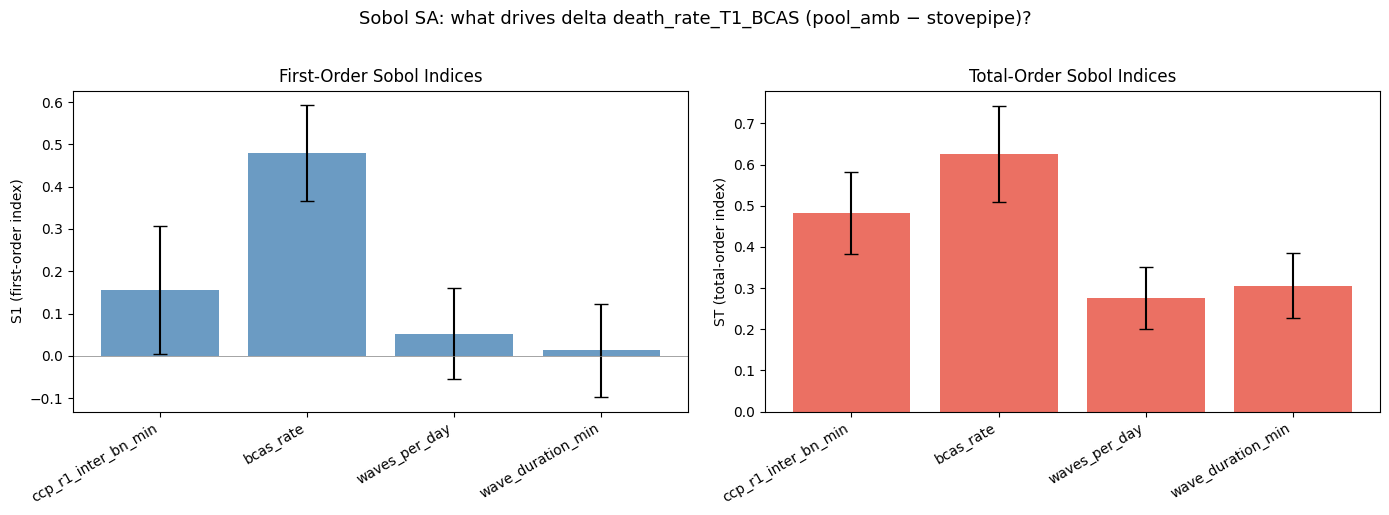

                        S1  S1_conf     ST  ST_conf
ccp_r1_inter_bn_min 0.1556   0.1510 0.4826   0.0995
bcas_rate           0.4792   0.1135 0.6262   0.1162
waves_per_day       0.0520   0.1075 0.2759   0.0742
wave_duration_min   0.0132   0.1105 0.3058   0.0793


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_pos = np.arange(len(UNCERTAINTIES))

# S1
axes[0].bar(x_pos, Si["S1"], yerr=Si["S1_conf"], capsize=5, color="steelblue", alpha=0.8)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(UNCERTAINTIES, rotation=30, ha="right")
axes[0].set_ylabel("S1 (first-order index)")
axes[0].set_title("First-Order Sobol Indices")
axes[0].axhline(0, color="grey", linewidth=0.5)

# ST
axes[1].bar(x_pos, Si["ST"], yerr=Si["ST_conf"], capsize=5, color="#e74c3c", alpha=0.8)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(UNCERTAINTIES, rotation=30, ha="right")
axes[1].set_ylabel("ST (total-order index)")
axes[1].set_title("Total-Order Sobol Indices")
axes[1].axhline(0, color="grey", linewidth=0.5)

fig.suptitle(f"Sobol SA: what drives delta {OUTCOME} (pool_amb − stovepipe)?", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# Summary table
summary = pd.DataFrame({"S1": Si["S1"], "S1_conf": Si["S1_conf"],
                         "ST": Si["ST"], "ST_conf": Si["ST_conf"]},
                        index=UNCERTAINTIES)
print(summary.to_string(float_format="%.4f"))

## Second-Order Indices (Pairwise Interactions)

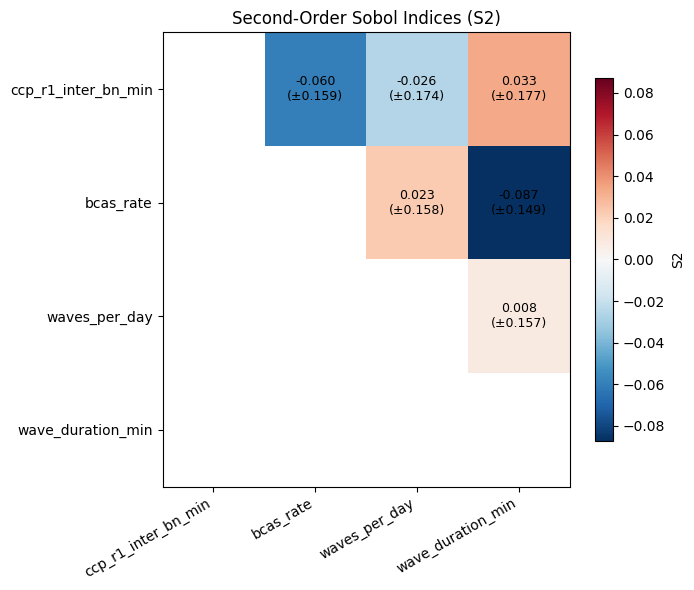


S2 matrix:
                     ccp_r1_inter_bn_min  bcas_rate  waves_per_day  wave_duration_min
ccp_r1_inter_bn_min                  NaN    -0.0599        -0.0258             0.0328
bcas_rate                            NaN        NaN         0.0227            -0.0873
waves_per_day                        NaN        NaN            NaN             0.0076
wave_duration_min                    NaN        NaN            NaN                NaN


In [7]:
S2 = pd.DataFrame(Si["S2"], index=UNCERTAINTIES, columns=UNCERTAINTIES)
S2_conf = pd.DataFrame(Si["S2_conf"], index=UNCERTAINTIES, columns=UNCERTAINTIES)

# Heatmap — SALib stores S2 in the upper triangle, diagonal is NaN
fig, ax = plt.subplots(figsize=(7, 6))
mask = np.tril(np.ones_like(S2, dtype=bool), k=0)  # hide diagonal + lower triangle
s2_masked = S2.where(~mask)

vabs = max(0.01, np.nanmax(np.abs(s2_masked.values.astype(float))))
im = ax.imshow(s2_masked.values.astype(float), cmap="RdBu_r", vmin=-vabs, vmax=vabs, aspect="auto")
ax.set_xticks(range(len(UNCERTAINTIES)))
ax.set_xticklabels(UNCERTAINTIES, rotation=30, ha="right")
ax.set_yticks(range(len(UNCERTAINTIES)))
ax.set_yticklabels(UNCERTAINTIES)
ax.set_title("Second-Order Sobol Indices (S2)")

for i in range(len(UNCERTAINTIES)):
    for j in range(len(UNCERTAINTIES)):
        if not mask[i, j]:
            v = S2.iloc[i, j]
            c = S2_conf.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.3f}\n(±{c:.3f})", ha="center", va="center", fontsize=9)

plt.colorbar(im, ax=ax, shrink=0.8, label="S2")
plt.tight_layout()
plt.show()

print("\nS2 matrix:")
print(S2.to_string(float_format="%.4f"))